# FraudShield · Credit card fraud detection

## Part A · Data understanding and preprocessing

Run from the project folder with `data/creditcard.csv` available. The grid search and k-NN scoring are the slowest cells. Part C divides the original holdout into an evaluation subset and a blind reserve.

Saved run: Python 3.12.14, scikit-learn 1.8.0, pandas 2.2.3, NumPy 2.3.5; dataset SHA-256: `76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89`. Identical random seeds do not guarantee identical scores across software or dataset versions.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

RANDOM_STATE = 42

print("Python environment:", sys.executable)
print("Working folder:", Path.cwd())
print("All imports successful!")
print("pandas:", pd.__version__, "| NumPy:", np.__version__, "| scikit-learn:", sklearn.__version__)

Python environment: C:\Projects\FraudShield\.venv\Scripts\python.exe
Working folder: C:\Projects\FraudShield
All imports successful!
pandas: 3.1.1 | NumPy: 2.5.5 | scikit-learn: 1.9.1


In [2]:
data_path = Path("data") / "creditcard.csv"
df = pd.read_csv(data_path)
print ("Dataset dimensions: ", df.shape)
display(df.head())
print(f"Number of transactions: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
print(f"Number of input features: {df.shape[1] - 1}")
df.info()

Dataset dimensions:  (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Number of transactions: 284,807
Number of columns: 31
Number of input features: 30
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807

In [3]:
missing_values = df.isna().sum()

display(
    missing_values.to_frame("missing values")
)

print("Total missing values:", missing_values.sum())

,missing values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Total missing values: 0


In [4]:
duplicate_mask = df.duplicated()

print ("Number of duplicate rows:", duplicate_mask.sum())

duplicate_counts = (
    df.loc[duplicate_mask,  "Class"]
    .value_counts()
    .reindex([0,1], fill_value =0)
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
)

display(duplicate_counts.to_frame("Duplicate copies"))

#show examples, including their original occurences
display(df[df.duplicated(keep=False)].head(10))


Number of duplicate rows: 1081


,Duplicate copies
Class,
Legitimate,1062
Fraudulent,19


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


In [5]:
df_clean = df.drop_duplicates().copy()

print("Original number of rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Remaining duplicates:", df_clean.duplicated().sum())

print("\nRemaining transactions by class:")
display(df_clean["Class"].value_counts().sort_index())


Original number of rows: 284807
Rows after removing duplicates: 283726
Rows removed: 1081
Remaining duplicates: 0

Remaining transactions by class:


Class
0    283253
1       473
Name: count, dtype: int64

In [6]:
print("Class labels:", df_clean["Class"].unique())
print("Missing values:", df_clean.isna().sum().sum())
print("Infinite values:", np.isinf(df_clean.select_dtypes(include="number")).sum().sum())
print("Negative amounts:", (df_clean["Amount"] < 0).sum())
print("Negative times:", (df_clean["Time"] < 0).sum())
print("Remaining duplicate copies:", df_clean.duplicated().sum())

assert set(df_clean["Class"].unique()) == {0, 1}, "Investigate unexpected labels."
assert df_clean.isna().sum().sum() == 0, "Investigate missing values."
assert np.isfinite(df_clean.to_numpy()).all(), "Investigate non-finite values."
assert (df_clean["Amount"] >= 0).all(), "Investigate negative amounts."
assert (df_clean["Time"] >= 0).all(), "Investigate negative times."
assert not df_clean.duplicated().any(), "Exact duplicate rows remain."
print("Basic data-quality checks passed.")


Class labels: [0 1]
Missing values: 0
Infinite values: 0
Negative amounts: 0
Negative times: 0
Remaining duplicate copies: 0
Basic data-quality checks passed.


,Count,Percentage
Legitimate,283253,99.8333
Fraudulent,473,0.1667


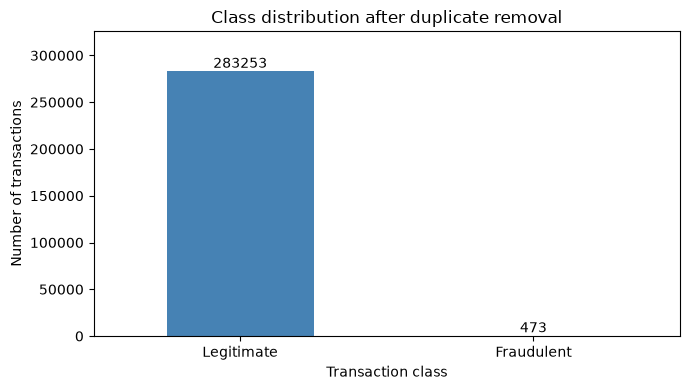

In [7]:
class_counts = df_clean["Class"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_counts / len(df_clean) * 100
})

class_summary.index = ["Legitimate", "Fraudulent"]

display(class_summary.round(4))

ax = class_summary["Count"].plot(
    kind="bar",
    color=["steelblue", "firebrick"],
    figsize=(7, 4),
    rot=0
)

ax.set_title("Class distribution after duplicate removal")
ax.set_xlabel("Transaction class")
ax.set_ylabel("Number of transactions")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

ax.margins(y=0.15)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold

RANDOM_STATE = 42

# Input features: every column except the answer
X = df_clean.drop(columns="Class")

# Target: the answer we want to predict
y = df_clean["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Cross-validation for later model development
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

split_summary = pd.DataFrame({
    "Transactions": [len(y_train), len(y_test)],
    "Fraud cases": [y_train.sum(), y_test.sum()],
    "Fraud percentage": [
        y_train.mean() * 100,
        y_test.mean() * 100
    ]
}, index=["Training", "Test"])

display(split_summary.round(4))

# Confirm that no original row belongs to both sets
assert X_train.index.intersection(X_test.index).empty
assert "Class" not in X_train.columns

Training features: (226980, 30)
Test features: (56746, 30)


,Transactions,Fraud cases,Fraud percentage
Training,226980,378,0.1665
Test,56746,95,0.1674


In [9]:
# These checks compare identifiers/features, not model performance on the test set.
assert X_train.columns.equals(X_test.columns)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert len(X_train) + len(X_test) == len(df_clean)

# Removing full-row duplicates would not catch identical inputs with different labels.
# Check inputs alone before using ordinary stratified folds.
feature_duplicate_count = int(X.duplicated().sum())
print("Extra identical-feature rows after cleaning:", feature_duplicate_count)
assert feature_duplicate_count == 0, (
    "Identical inputs remain. Inspect conflicting labels and use group-aware splits "
    "before continuing; do not silently drop the conflicting rows."
)

# Materialize one fixed set of folds for fair comparisons in Part B.
cv_splits = list(cv.split(X_train, y_train))
fold_rows = []
for fold, (fit_idx, valid_idx) in enumerate(cv_splits, start=1):
    assert np.intersect1d(fit_idx, valid_idx).size == 0
    assert len(fit_idx) + len(valid_idx) == len(X_train)
    assert y_train.iloc[fit_idx].nunique() == 2
    assert y_train.iloc[valid_idx].nunique() == 2
    fold_rows.append({
        "Fold": fold,
        "Fit rows": len(fit_idx),
        "Validation rows": len(valid_idx),
        "Fit fraud cases": int(y_train.iloc[fit_idx].sum()),
        "Validation fraud cases": int(y_train.iloc[valid_idx].sum())
    })

# Every development row must be validated exactly once.
validation_positions = np.concatenate([valid_idx for _, valid_idx in cv_splits])
assert np.array_equal(np.sort(validation_positions), np.arange(len(X_train)))
display(pd.DataFrame(fold_rows).set_index("Fold"))
print("Split and fold checks passed. Keep the 20% holdout out of model development; Part C defines its two evaluation subsets.")

Extra identical-feature rows after cleaning: 0


,Fit rows,Validation rows,Fit fraud cases,Validation fraud cases
Fold,,,,
1,181584,45396,303,75
2,181584,45396,303,75
3,181584,45396,302,76
4,181584,45396,302,76
5,181584,45396,302,76


Split and fold checks passed. Keep the 20% holdout out of model development; Part C defines its two evaluation subsets.


In [10]:
feature_summary = X_train.describe().T

feature_summary["range"] = (
    feature_summary["max"] - feature_summary["min"]
)

display(
    feature_summary[
        ["mean", "std", "min", "25%", "50%", "75%", "max", "range"]
    ].round(3)
)

,mean,std,min,25%,50%,75%,max,range
Time,94900.224,47488.214,0.000,54241.750,84816.000,139364.250,172792.000,172792.000
V1,0.005,1.947,-56.408,-0.916,0.018,1.315,2.455,58.862
V2,-0.006,1.650,-72.716,-0.601,0.064,0.801,22.058,94.773
V3,0.002,1.507,-33.681,-0.887,0.178,1.027,9.383,43.064
V4,-0.002,1.417,-5.683,-0.849,-0.022,0.741,16.875,22.559
V5,0.005,1.360,-32.092,-0.689,-0.052,0.615,34.802,66.894
V6,-0.002,1.323,-26.161,-0.769,-0.276,0.397,21.393,47.554
V7,0.001,1.200,-43.557,-0.552,0.041,0.572,34.303,77.860
V8,-0.000,1.169,-73.217,-0.209,0.022,0.325,20.007,93.224
V9,-0.003,1.094,-13.434,-0.644,-0.053,0.594,15.595,29.029


Constant input features: []


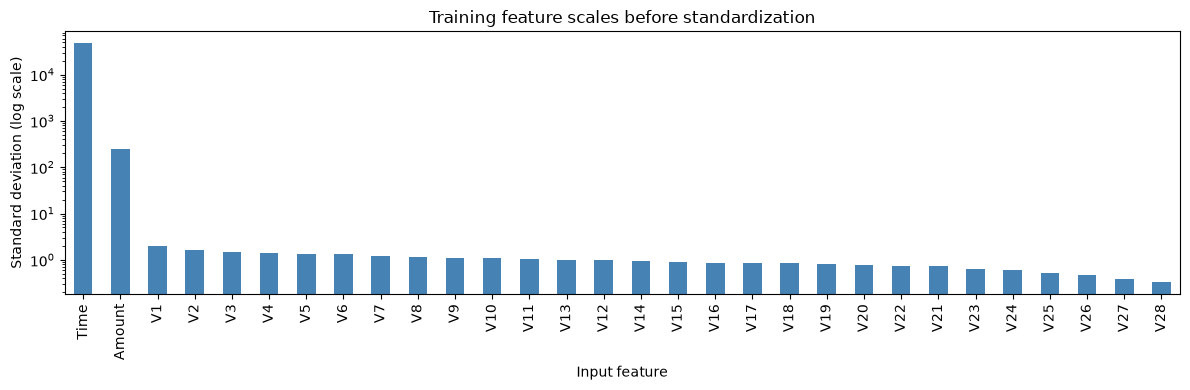

,mean,median,std,min,max
Time,94900.224,84816.00,47488.214,0.0,172792.00
Amount,88.387,22.08,245.767,0.0,19656.53


In [11]:
constant_features = X_train.columns[X_train.nunique() <= 1].tolist()
print("Constant input features:", constant_features)

# The logarithmic axis makes large differences in standard deviation readable.
std_by_feature = X_train.std().sort_values(ascending=False)
ax = std_by_feature[std_by_feature > 0].plot.bar(
    figsize=(12, 4), color="steelblue", logy=True
)
ax.set_title("Training feature scales before standardization")
ax.set_xlabel("Input feature")
ax.set_ylabel("Standard deviation (log scale)")
plt.tight_layout()
plt.show()

display(X_train[["Time", "Amount"]].agg(["mean", "median", "std", "min", "max"]).T.round(3))


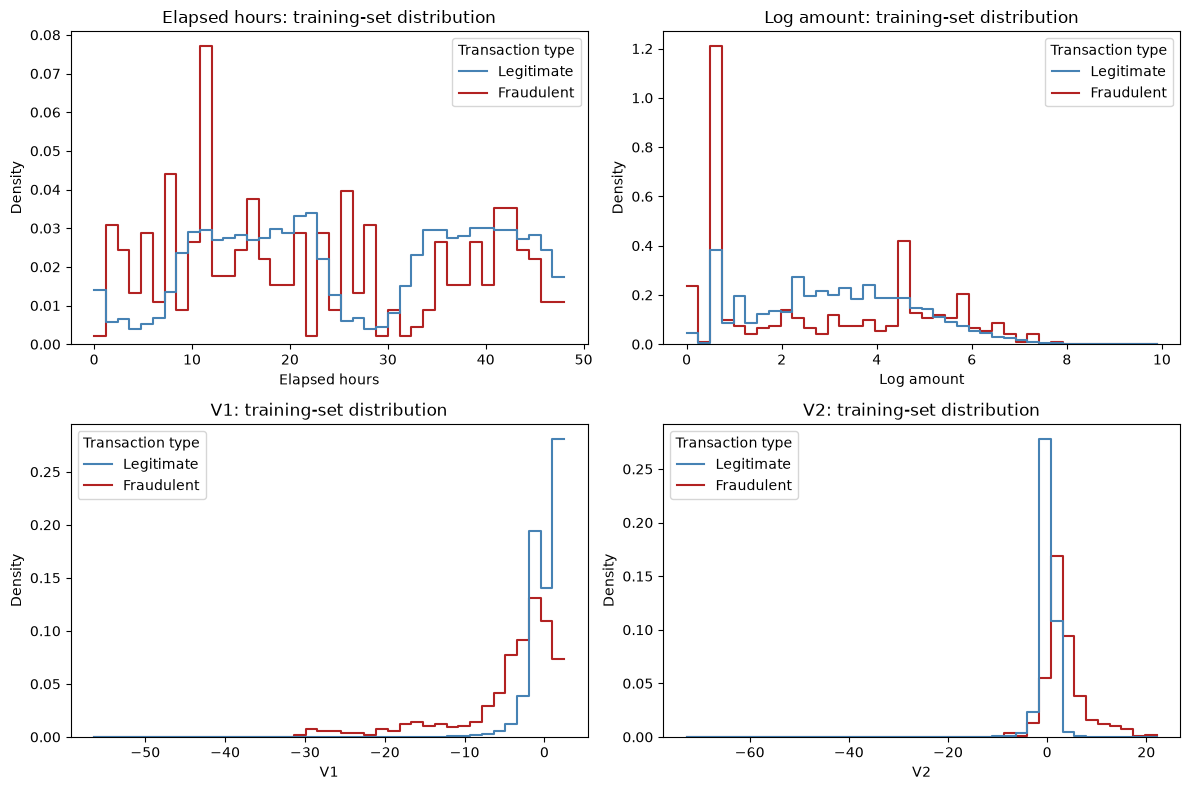

In [12]:
# A separate table used only for exploration
train_eda = X_train.copy()

train_eda["Transaction type"] = y_train.map({
    0: "Legitimate",
    1: "Fraudulent"
})

# These columns are for plotting only
train_eda["Elapsed hours"] = train_eda["Time"] / 3600
train_eda["Log amount"] = np.log1p(train_eda["Amount"])

plot_columns = ["Elapsed hours", "Log amount", "V1", "V2"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, ax in zip(plot_columns, axes.flat):
    sns.histplot(
        data=train_eda,
        x=column,
        hue="Transaction type",
        hue_order=["Legitimate", "Fraudulent"],
        palette={"Legitimate": "steelblue", "Fraudulent": "firebrick"},
        bins=40,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=ax
    )

    ax.set_title(f"{column}: training-set distribution")

plt.tight_layout()
plt.show()


In [13]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def build_model_pipeline(model, scale=True):
    """Return an unfitted, independent model pipeline for training/CV."""
    steps = []
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", clone(model)))
    return Pipeline(steps)


In [14]:
fit_idx, valid_idx = cv_splits[0]
fold_fit = X_train.iloc[fit_idx]
fold_valid = X_train.iloc[valid_idx]

demo_scaler = StandardScaler()
demo_fit_scaled = demo_scaler.fit_transform(fold_fit)
demo_valid_scaled = demo_scaler.transform(fold_valid)

nonconstant = fold_fit.var(ddof=0).to_numpy() > 0
assert np.isfinite(demo_fit_scaled).all()
assert np.isfinite(demo_valid_scaled).all()
assert np.allclose(demo_fit_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(demo_fit_scaled.std(axis=0, ddof=0)[nonconstant], 1, atol=1e-10)

scale_check = pd.DataFrame({
    "Fit mean before": fold_fit.mean(),
    "Fit std before": fold_fit.std(ddof=0),
    "Fit mean after": demo_fit_scaled.mean(axis=0),
    "Fit std after": demo_fit_scaled.std(axis=0, ddof=0),
    "Validation mean after": demo_valid_scaled.mean(axis=0)
}, index=X_train.columns)
display(scale_check.loc[["Time", "Amount", "V1", "V2"]].round(4))
print("Scaling checks passed. Validation data used transform only.")

# Avoid accidentally reusing demonstration arrays in later model selection.
del demo_scaler, demo_fit_scaled, demo_valid_scaled, fold_fit, fold_valid


,Fit mean before,Fit std before,Fit mean after,Fit std after,Validation mean after
Time,94889.4008,47488.0788,0.0,1.0,0.0011
Amount,87.9121,241.7520,0.0,1.0,0.0098
V1,0.0034,1.9481,0.0,1.0,0.0043
V2,-0.0029,1.6386,0.0,1.0,-0.0082


Scaling checks passed. Validation data used transform only.


# Part B · Baseline models
We compare a linear classifier (Logistic Regression), a single Decision Tree, two different tree ensembles (Random Forest averages trees; Histogram Gradient Boosting builds successive corrections), and a distance-based classifier (k-NN). These test different assumptions about fraud while using the same observations. We scale the inputs for Logistic Regression and k-NN inside each fold.

Our primary selection metric is **average precision (AP)**: it summarizes precision as recall increases, useful when false alerts can overwhelm rare frauds. The internal key `pr_auc` refers to scikit-learn’s **average_precision**, not trapezoidal area. ROC-AUC measures ranking against negatives; it does not tell us how many alerts are false at a chosen cutoff.

In [15]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import (
    make_scorer, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, precision_recall_curve
)

# same metrics for every model
scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score),
    "f1": make_scorer(f1_score),
}

N_JOBS = 4 

### Parameter choices

- **Logistic Regression:** `C` (regularisation) and `class_weight`. `balanced` gives fraud about 600x more weight (ratio of legit to fraud in a fold).
- **Decision Tree:** `max_depth` and `min_samples_leaf` to stop the tree from memorising the ~300 frauds per fold.
- **Random Forest:** a full forest took ~4.5 min per fit, so each tree uses a 30% bootstrap sample (`max_samples=0.3`). We tune `min_samples_leaf` and class weight.
- **Gradient Boosting:** learning rate and tree size. Early stopping monitors loss on an internal 10% of each fitting fold, up to 500 iterations; the external grid selects settings by AP.
- **k-NN:** number of neighbours, with distance weighting. Needs scaling. No class_weight option.

In [16]:
model_specs = {
    "Logistic Regression": dict(
        model=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        scale=True,
        grid={"model__C": [0.01, 0.1, 1, 10],
              "model__class_weight": [None, "balanced"]},
    ),
    "Decision Tree": dict(
        model=DecisionTreeClassifier(random_state=RANDOM_STATE),
        scale=False,  # trees don't need scaling
        grid={"model__max_depth": [4, 8, 12],
              "model__min_samples_leaf": [1, 20],
              "model__class_weight": [None, "balanced"]},
    ),
    "Random Forest": dict(
        model=RandomForestClassifier(n_estimators=100, max_samples=0.3, max_features="sqrt",
                                     n_jobs=1, random_state=RANDOM_STATE),
        scale=False,
        grid={"model__min_samples_leaf": [1, 5],
              "model__class_weight": [None, "balanced_subsample"]},
    ),
    "Gradient Boosting": dict(
        model=HistGradientBoostingClassifier(max_iter=500, early_stopping=True,
                                             validation_fraction=0.1, n_iter_no_change=20,
                                             l2_regularization=1.0, random_state=RANDOM_STATE),
        scale=False,
        grid={"model__learning_rate": [0.05, 0.1],
              "model__max_leaf_nodes": [15, 31],
              "model__class_weight": [None, "balanced"]},
    ),
    "k-NN": dict(
        model=KNeighborsClassifier(weights="distance", n_jobs=1),
        scale=True,
        grid={"model__n_neighbors": [5, 15, 35]},
        train_score=False,  # train score is always ~1 for k-NN and takes 20+ min to compute
    ),
}

for name, spec in model_specs.items():
    n_combos = int(np.prod([len(v) for v in spec["grid"].values()]))
    print(f"{name:<20} {n_combos:>2} settings x {len(cv_splits)} folds = {n_combos * len(cv_splits)} fits")

Logistic Regression   8 settings x 5 folds = 40 fits
Decision Tree        12 settings x 5 folds = 60 fits
Random Forest         4 settings x 5 folds = 20 fits
Gradient Boosting     8 settings x 5 folds = 40 fits
k-NN                  3 settings x 5 folds = 15 fits


### Grid search
Use the five fixed splits from Part A for every candidate. Choose each model’s settings by mean validation AP and refit the selected pipeline on the full training set. Wall time depends on the machine; k-NN is inexpensive to fit but expensive to score.

In [17]:
searches = {}
for name, spec in model_specs.items():
    start = time.perf_counter()
    search = GridSearchCV(
        estimator=build_model_pipeline(spec["model"], scale=spec["scale"]),
        param_grid=spec["grid"],
        scoring=scoring,
        refit="pr_auc",
        cv=cv_splits,
        return_train_score=spec.get("train_score", True),
        n_jobs=N_JOBS, error_score="raise",
    )
    search.fit(X_train, y_train)
    searches[name] = search
    best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:<20} best CV AP = {search.best_score_:.4f}  "
          f"({time.perf_counter() - start:.0f}s)  {best_params}")

Logistic Regression  best CV AP = 0.7548  (13s)  {'C': 0.1, 'class_weight': 'balanced'}
Decision Tree        best CV AP = 0.7623  (73s)  {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 20}
Random Forest        best CV AP = 0.8282  (173s)  {'class_weight': None, 'min_samples_leaf': 1}
Gradient Boosting    best CV AP = 0.8374  (128s)  {'class_weight': None, 'learning_rate': 0.05, 'max_leaf_nodes': 31}
k-NN                 best CV AP = 0.8160  (180s)  {'n_neighbors': 15}


### Full grid results
A large positive training-minus-validation AP gap is evidence of possible overfitting. Compare it with the actual validation score. k-NN training scores were deliberately skipped; a missing gap does not mean zero overfitting.

In [18]:
def grid_table(search):
    res = pd.DataFrame(search.cv_results_)
    params = res["params"].apply(lambda p: ", ".join(f"{k.replace('model__', '')}={v}" for k, v in p.items()))
    table = pd.DataFrame({
        "Setting": params,
        "Val AP": res["mean_test_pr_auc"],
        "Val AP std": res["std_test_pr_auc"],
        "Train AP": res.get("mean_train_pr_auc", np.nan),
        "Val recall@0.5": res["mean_test_recall"],
        "Val precision@0.5": res["mean_test_precision"],
    })
    table["Train - Val gap"] = table["Train AP"] - table["Val AP"]
    return table.sort_values("Val AP", ascending=False).reset_index(drop=True)

for name, search in searches.items():
    print(name)
    display(grid_table(search).round(4))

Logistic Regression


,Setting,Val AP,Val AP std,Train AP,Val recall@0.5,Val precision@0.5,Train - Val gap
0,"C=0.1, class_weight=balanced",0.7548,0.0261,0.7568,0.9179,0.0608,0.0019
1,"C=1, class_weight=balanced",0.7538,0.0270,0.7563,0.9179,0.0605,0.0026
2,"C=0.01, class_weight=None",0.7537,0.0263,0.7603,0.5792,0.8774,0.0066
3,"C=10, class_weight=balanced",0.7536,0.0271,0.7562,0.9179,0.0605,0.0026
4,"C=0.01, class_weight=balanced",0.7536,0.0257,0.7560,0.9074,0.0616,0.0024
5,"C=0.1, class_weight=None",0.7532,0.0317,0.7659,0.5951,0.8640,0.0127
6,"C=1, class_weight=None",0.7527,0.0325,0.7661,0.6056,0.8633,0.0134
7,"C=10, class_weight=None",0.7521,0.0330,0.7660,0.6056,0.8633,0.0139


Decision Tree


,Setting,Val AP,Val AP std,Train AP,Val recall@0.5,Val precision@0.5,Train - Val gap
0,"class_weight=None, max_depth=8, min_samples_le...",0.7623,0.0350,0.8422,0.7698,0.8642,0.0799
1,"class_weight=None, max_depth=12, min_samples_l...",0.7579,0.0349,0.8661,0.7698,0.8642,0.1082
2,"class_weight=None, max_depth=4, min_samples_le...",0.7546,0.0373,0.7890,0.7910,0.8352,0.0345
3,"class_weight=None, max_depth=4, min_samples_le...",0.7500,0.0360,0.7997,0.7990,0.8485,0.0497
4,"class_weight=balanced, max_depth=12, min_sampl...",0.7359,0.0556,0.8722,0.8043,0.1933,0.1364
5,"class_weight=None, max_depth=8, min_samples_le...",0.6518,0.0314,0.8736,0.7431,0.8843,0.2218
6,"class_weight=balanced, max_depth=8, min_sample...",0.6306,0.0561,0.7321,0.8201,0.1144,0.1015
7,"class_weight=None, max_depth=12, min_samples_l...",0.6298,0.0368,0.9285,0.7431,0.8357,0.2987
8,"class_weight=balanced, max_depth=12, min_sampl...",0.5239,0.0497,0.7485,0.7911,0.2431,0.2245
9,"class_weight=balanced, max_depth=8, min_sample...",0.4978,0.0533,0.6391,0.8148,0.1242,0.1413


Random Forest


,Setting,Val AP,Val AP std,Train AP,Val recall@0.5,Val precision@0.5,Train - Val gap
0,"class_weight=None, min_samples_leaf=1",0.8282,0.0382,0.9788,0.7592,0.9281,0.1506
1,"class_weight=balanced_subsample, min_samples_l...",0.8209,0.0333,0.9815,0.7169,0.9341,0.1606
2,"class_weight=None, min_samples_leaf=5",0.8189,0.0396,0.9184,0.7301,0.8856,0.0994
3,"class_weight=balanced_subsample, min_samples_l...",0.8028,0.0366,0.9346,0.7725,0.8619,0.1318


Gradient Boosting


,Setting,Val AP,Val AP std,Train AP,Val recall@0.5,Val precision@0.5,Train - Val gap
0,"class_weight=None, learning_rate=0.05, max_lea...",0.8374,0.0273,0.9893,0.7566,0.9410,0.1520
1,"class_weight=None, learning_rate=0.05, max_lea...",0.8326,0.0239,0.9846,0.7592,0.9271,0.1520
2,"class_weight=None, learning_rate=0.1, max_leaf...",0.8191,0.0242,0.9867,0.7513,0.9349,0.1676
3,"class_weight=None, learning_rate=0.1, max_leaf...",0.8146,0.0214,0.9822,0.7645,0.9361,0.1675
4,"class_weight=balanced, learning_rate=0.1, max_...",0.7541,0.0238,0.8758,0.8519,0.6313,0.1216
5,"class_weight=balanced, learning_rate=0.05, max...",0.7534,0.0222,0.8710,0.8492,0.5380,0.1177
6,"class_weight=balanced, learning_rate=0.1, max_...",0.7492,0.0224,0.8547,0.8704,0.4087,0.1056
7,"class_weight=balanced, learning_rate=0.05, max...",0.7480,0.0224,0.8491,0.8677,0.3308,0.1011


k-NN


,Setting,Val AP,Val AP std,Train AP,Val recall@0.5,Val precision@0.5,Train - Val gap
0,n_neighbors=15,0.8160,0.0615,NaN,0.7726,0.9034,NaN
1,n_neighbors=35,0.8101,0.0517,NaN,0.7540,0.8641,NaN
2,n_neighbors=5,0.8099,0.0472,NaN,0.7725,0.9227,NaN


### Best settings: average precision, ROC-AUC, precision, recall and F1
The summary uses the metrics for the candidate selected by AP. The grid’s precision, recall and F1 use each estimator’s `predict` method. The later confusion counts explicitly flag scores ≥ 0.50; exact ties can be handled differently by `predict`. Fold standard deviations are descriptive, not confidence intervals.

Random-guess AP (fraud rate in training data): 0.0017


,pr_auc mean,pr_auc std,roc_auc mean,roc_auc std,precision mean,precision std,recall mean,recall std,f1 mean,f1 std,train pr_auc,fit time (s/fold),overfit gap
Model,,,,,,,,,,,,,
Gradient Boosting,0.8374,0.0273,0.9804,0.0073,0.9410,0.0327,0.7566,0.0594,0.8363,0.0285,0.9893,2.9717,0.1520
Random Forest,0.8282,0.0382,0.9401,0.0214,0.9281,0.0322,0.7592,0.0823,0.8333,0.0586,0.9788,30.7743,0.1506
k-NN,0.8160,0.0615,0.9257,0.0245,0.9034,0.0411,0.7726,0.0807,0.8313,0.0603,NaN,0.1988,NaN
Decision Tree,0.7623,0.0350,0.9324,0.0298,0.8642,0.0243,0.7698,0.0607,0.8129,0.0360,0.8422,4.6295,0.0799
Logistic Regression,0.7548,0.0261,0.9814,0.0081,0.0608,0.0071,0.9179,0.0245,0.1139,0.0124,0.7568,0.9216,0.0019


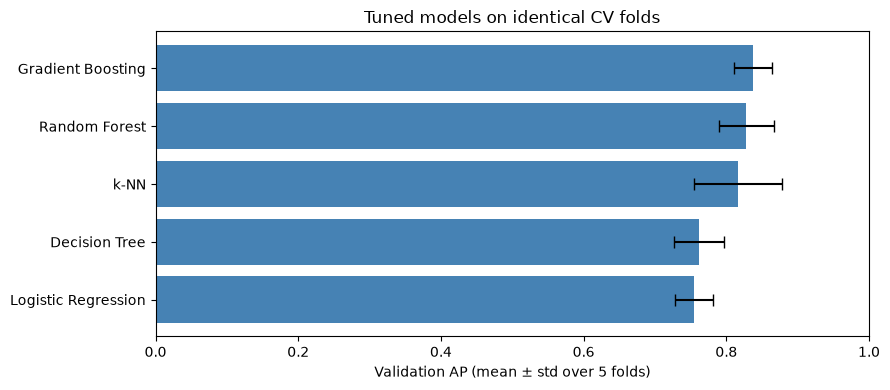

In [19]:
summary_rows = []
for name, search in searches.items():
    res = search.cv_results_
    i = search.best_index_
    row = {"Model": name}
    for metric in scoring:
        row[f"{metric} mean"] = res[f"mean_test_{metric}"][i]
        row[f"{metric} std"] = res[f"std_test_{metric}"][i]
    row["train pr_auc"] = res["mean_train_pr_auc"][i] if "mean_train_pr_auc" in res else np.nan
    row["fit time (s/fold)"] = res["mean_fit_time"][i]
    summary_rows.append(row)

cv_summary = (pd.DataFrame(summary_rows).set_index("Model")
              .sort_values("pr_auc mean", ascending=False))
cv_summary["overfit gap"] = cv_summary["train pr_auc"] - cv_summary["pr_auc mean"]

# random guess AP = fraud rate
print(f"Random-guess AP (fraud rate in training data): {y_train.mean():.4f}")
display(cv_summary.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
order = cv_summary.index[::-1]
ax.barh(order, cv_summary.loc[order, "pr_auc mean"], xerr=cv_summary.loc[order, "pr_auc std"],
        color="steelblue", capsize=4)
ax.set_xlabel("Validation AP (mean ± std over 5 folds)")
ax.set_title("Tuned models on identical CV folds")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

### Out-of-fold predictions
Each row is scored by a model fitted without that row. However, its label participated in choosing the hyperparameters through Part B’s grid search. These pooled scores are useful for development and threshold selection; they are not independent final performance estimates. Pooled AP can differ from mean fold AP.

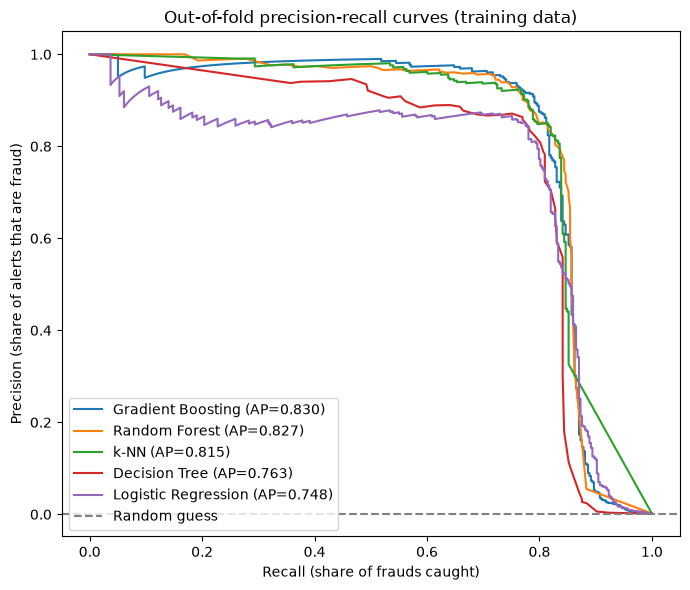

,Frauds caught (TP),Frauds missed (FN),False alarms (FP),Recall,Precision
Model,,,,,
Gradient Boosting,286,92,19,0.757,0.938
Random Forest,288,90,25,0.762,0.920
k-NN,292,86,31,0.772,0.904
Decision Tree,291,87,46,0.770,0.864
Logistic Regression,347,31,5434,0.918,0.060


In [20]:
best_pipelines = {name: s.best_estimator_ for name, s in searches.items()}

oof_proba = {}
for name, search in searches.items():
    oof_proba[name] = cross_val_predict(
        clone(search.best_estimator_), X_train, y_train,
        cv=cv_splits, method="predict_proba", n_jobs=N_JOBS
    )[:, 1]
oof_proba = pd.DataFrame(oof_proba, index=X_train.index)

# Unrounded decision scores preserve ranking when predict_proba saturates.
# Models without a decision function already rank by their positive-class probabilities.
oof_rank = oof_proba.copy()
for name, pipe in best_pipelines.items():
    if hasattr(pipe, "decision_function"):
        oof_rank[name] = cross_val_predict(
            clone(pipe), X_train, y_train, cv=cv_splits,
            method="decision_function", n_jobs=N_JOBS
        )
# Confirm that OOF ranking uses the same score definition as the grid.
for name in cv_summary.index:
    fold_ap = [average_precision_score(y_train.iloc[v], oof_rank[name].iloc[v]) for _, v in cv_splits]
    if abs(np.mean(fold_ap) - cv_summary.loc[name, "pr_auc mean"]) > 0.005:
        print(f"Review {name}: mean fold AP differs from grid by more than 0.005.")
fig, ax = plt.subplots(figsize=(7, 6))
for name in cv_summary.index:
    precision, recall, _ = precision_recall_curve(y_train, oof_rank[name])
    ap = average_precision_score(y_train, oof_rank[name])
    ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label="Random guess")
ax.set_xlabel("Recall (share of frauds caught)")
ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.set_title("Out-of-fold precision-recall curves (training data)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

# results at threshold 0.5
rows = []
for name in cv_summary.index:
    pred = (oof_proba[name] >= 0.5).astype(int)
    tp = int(((pred == 1) & (y_train == 1)).sum())
    fp = int(((pred == 1) & (y_train == 0)).sum())
    fn = int(((pred == 0) & (y_train == 1)).sum())
    rows.append({"Model": name, "Frauds caught (TP)": tp, "Frauds missed (FN)": fn,
                 "False alarms (FP)": fp, "Recall": tp / (tp + fn),
                 "Precision": tp / (tp + fp) if tp + fp else 0.0})
display(pd.DataFrame(rows).set_index("Model").round(3))

### Interpreting the Part B comparison
Use the mean fold AP table to nominate a model before independent evaluation. The error bars show variation across folds; overlapping standard deviations are not a significance test. Compare depth and leaf size using the actual Decision Tree grid (4, 8, or 12 levels). Class weights can change recall and precision at 0.5 even when AP changes little; they do not simply move a cutoff. Inspect the rows for each model before generalizing.

A PR curve shows the trade-off for one model. It cannot establish whether different models missed the same transactions. Part C counts those errors directly.

In [21]:
leader = cv_summary.index[0]
runner = cv_summary.index[1]
print(f"Highest mean fold AP: {leader} ({cv_summary.loc[leader, 'pr_auc mean']:.4f}), "
      f"followed by {runner} ({cv_summary.loc[runner, 'pr_auc mean']:.4f}). "
      "This is a descriptive ranking, not a test of superiority.")
coef = pd.Series(best_pipelines["Logistic Regression"].named_steps["model"].coef_[0],
                 index=X_train.columns)
top = coef.abs().nlargest(5).index
display(coef.loc[top].rename("Coefficient per training standard deviation").to_frame().round(3))
print("Positive coefficients increase fitted fraud log-odds with other inputs held fixed. "
      "The anonymized variables limit interpretation; these are not causal effects.")

Highest mean fold AP: Gradient Boosting (0.8374), followed by Random Forest (0.8282). This is a descriptive ranking, not a test of superiority.


,Coefficient per training standard deviation
V14,-1.438
Amount,1.273
V4,1.236
V1,1.228
V12,-1.208


Positive coefficients increase fitted fraud log-odds with other inputs held fixed. The anonymized variables limit interpretation; these are not causal effects.


### Part B: what the numbers show
The table below is computed from the grid results above. It checks three things the brief asks us to recognise: misleading metrics (ROC-AUC vs AP), the effect of class weighting, and overfitting.

In [22]:
rank_check = pd.DataFrame({
    "AP rank": cv_summary["pr_auc mean"].rank(ascending=False).astype(int),
    "ROC-AUC rank": cv_summary["roc_auc mean"].rank(ascending=False).astype(int),
})

# best validation AP with and without class weighting, for models where it was tuned
weight_rows = {}
for name, search in searches.items():
    res = pd.DataFrame(search.cv_results_)
    if "param_model__class_weight" not in res:
        continue
    weighted = res["param_model__class_weight"].notna()
    weight_rows[name] = {
        "Best AP, no weighting": res.loc[~weighted, "mean_test_pr_auc"].max(),
        "Best AP, weighted": res.loc[weighted, "mean_test_pr_auc"].max(),
    }
weight_check = pd.DataFrame(weight_rows).T
weight_check["Change"] = weight_check["Best AP, weighted"] - weight_check["Best AP, no weighting"]

tree = pd.DataFrame(searches["Decision Tree"].cv_results_)
deepest = tree.loc[(tree["param_model__max_depth"] == 12) & (tree["param_model__min_samples_leaf"] == 1)
                   & tree["param_model__class_weight"].isna()].iloc[0]
chosen = tree.loc[searches["Decision Tree"].best_index_]

display(rank_check)
display(weight_check.round(4))
print(f"Decision Tree, depth 12 / leaf 1: train AP {deepest.mean_train_pr_auc:.3f}, "
      f"validation AP {deepest.mean_test_pr_auc:.3f} (gap {deepest.mean_train_pr_auc - deepest.mean_test_pr_auc:.3f})")
print(f"Decision Tree, selected: train AP {chosen.mean_train_pr_auc:.3f}, "
      f"validation AP {chosen.mean_test_pr_auc:.3f} (gap {chosen.mean_train_pr_auc - chosen.mean_test_pr_auc:.3f})")

,AP rank,ROC-AUC rank
Model,,
Gradient Boosting,1,2
Random Forest,2,3
k-NN,3,5
Decision Tree,4,4
Logistic Regression,5,1


,"Best AP, no weighting","Best AP, weighted",Change
Logistic Regression,0.7537,0.7548,0.0011
Decision Tree,0.7623,0.7359,-0.0265
Random Forest,0.8282,0.8209,-0.0073
Gradient Boosting,0.8374,0.7541,-0.0833


Decision Tree, depth 12 / leaf 1: train AP 0.928, validation AP 0.630 (gap 0.299)
Decision Tree, selected: train AP 0.842, validation AP 0.762 (gap 0.080)


- **ROC-AUC is misleading here:** Logistic Regression ranks first or second on ROC-AUC but last on AP. At 0.50 it catches the most frauds but raises thousands of false alerts (table above). ROC-AUC hides this because the false alerts are a tiny share of ~226k legitimate rows.
- **Class weighting:** it barely changes AP for Logistic Regression but lowers AP for every tree model. For Logistic Regression it mainly changes which transactions cross 0.50, so the cutoff needs to be chosen deliberately (Part D).
- **Overfitting:** the unrestricted Decision Tree memorises its training folds. Limiting depth and leaf size closes most of the gap and gives a better validation score. Random Forest and Gradient Boosting also fit their training folds closely, but still have the best validation AP.

# Part C · Evaluation and improvement
**Plan fixed before scoring:** compare all five fitted models at a common score cutoff of 0.50. Nominate one model by Part B’s mean fold AP; for that model also try a cutoff that maximizes training out-of-fold F1. F1 gives precision and recall equal importance; it does not represent a monetary cost. No settings or thresholds are selected from Part C results.

To obtain independent results now **and** keep unseen data for Part D, divide the original 20% holdout into two equally sized stratified subsets. This gives approximately 80% training, 10% Part C evaluation, and 10% blind final evaluation. Every Part C model sees the same evaluation rows. The trade-off is fewer frauds per evaluation: report counts alongside percentages. From now on, use only `X_final` / `y_final` for the final check after the Part D question and protocol are fixed; do not evaluate on the combined original holdout.

In [23]:
X_eval, X_final, y_eval, y_final = train_test_split(
    X_test, y_test, test_size=0.50, stratify=y_test, random_state=RANDOM_STATE
)
assert X_train.index.intersection(X_eval.index.union(X_final.index)).empty
assert X_eval.index.intersection(X_final.index).empty
assert len(X_eval) + len(X_final) == len(X_test)
assert oof_proba.index.equals(y_train.index)
selected = cv_summary.index[0]  # already sorted by mean validation AP
pr, rc, cuts = precision_recall_curve(y_train, oof_proba[selected])
# The last precision/recall pair has no corresponding threshold.
f = 2 * pr[:-1] * rc[:-1] / np.maximum(pr[:-1] + rc[:-1], 1e-15)
best_cut = float(cuts[np.flatnonzero(f == f.max())[-1]])  # highest cutoff breaks a tie
print(f"Locked model: {selected}; F1 cutoff from training only: {best_cut:.6g}")
print(f"Part C: {len(y_eval):,} rows, {int(y_eval.sum())} frauds. Final reserve: {len(y_final):,} rows.")

Locked model: Gradient Boosting; F1 cutoff from training only: 0.232107
Part C: 28,373 rows, 48 frauds. Final reserve: 28,373 rows.


### Compare the models on unseen transactions
AP and ROC-AUC use the full ranking of scores. Precision, recall, F1 and the confusion counts use the specified cutoff. **Precision** answers “How many alerts were actually fraud?” **Recall** answers “How much of the fraud did we catch?” The simple reference always predicts legitimate; its AP is the fraud rate and it catches no fraud.

In [24]:
from sklearn.metrics import confusion_matrix

def evaluate_scores(labels, scores, cutoff, ranking=None):
    scores = np.asarray(scores)
    assert scores.shape == (len(labels),) and np.isfinite(scores).all()
    ranking = scores if ranking is None else np.asarray(ranking)
    assert ranking.shape == scores.shape and np.isfinite(ranking).all()
    alerts = scores >= cutoff
    tn, fp, fn, tp = confusion_matrix(labels, alerts, labels=[0, 1]).ravel()
    return {"Cutoff": cutoff, "AP": average_precision_score(labels, ranking),
            "ROC-AUC": roc_auc_score(labels, ranking),
            "Precision": precision_score(labels, alerts, zero_division=0),
            "Recall": recall_score(labels, alerts), "F1": f1_score(labels, alerts),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp, "Alerts": fp + tp}

eval_scores = pd.DataFrame(index=X_eval.index)
eval_rank = pd.DataFrame(index=X_eval.index)
for name, pipe in best_pipelines.items():
    positive = list(pipe.classes_).index(1)
    eval_scores[name] = pipe.predict_proba(X_eval)[:, positive]
    eval_rank[name] = pipe.decision_function(X_eval) if hasattr(pipe, "decision_function") else eval_scores[name]

assert eval_scores.index.equals(y_eval.index)
results = {name: evaluate_scores(y_eval, eval_scores[name], 0.5, eval_rank[name]) for name in cv_summary.index}
reference = "Always legitimate"
alternative = f"{selected} (training F1 cutoff)"
results[reference] = evaluate_scores(y_eval, np.zeros(len(y_eval)), 0.5)
results[alternative] = evaluate_scores(y_eval, eval_scores[selected], best_cut, eval_rank[selected])
evaluation = pd.DataFrame.from_dict(results, orient="index")
assert (evaluation.TP + evaluation.FN == y_eval.sum()).all()
assert (evaluation.TN + evaluation.FP == (y_eval == 0).sum()).all()
display(evaluation.round(4))

,Cutoff,AP,ROC-AUC,Precision,Recall,F1,TN,FP,FN,TP,Alerts
Gradient Boosting,0.5000,0.7599,0.9597,0.9722,0.7292,0.8333,28324,1,13,35,36
Random Forest,0.5000,0.7438,0.9031,0.9394,0.6458,0.7654,28323,2,17,31,33
k-NN,0.5000,0.7534,0.8851,0.9677,0.6250,0.7595,28324,1,18,30,31
Decision Tree,0.5000,0.6721,0.8909,0.8611,0.6458,0.7381,28320,5,17,31,36
Logistic Regression,0.5000,0.6587,0.9470,0.0572,0.8333,0.1071,27666,659,8,40,699
Always legitimate,0.5000,0.0017,0.5000,0.0000,0.0000,0.0000,28325,0,48,0,0
Gradient Boosting (training F1 cutoff),0.2321,0.7599,0.9597,0.8974,0.7292,0.8046,28321,4,13,35,39


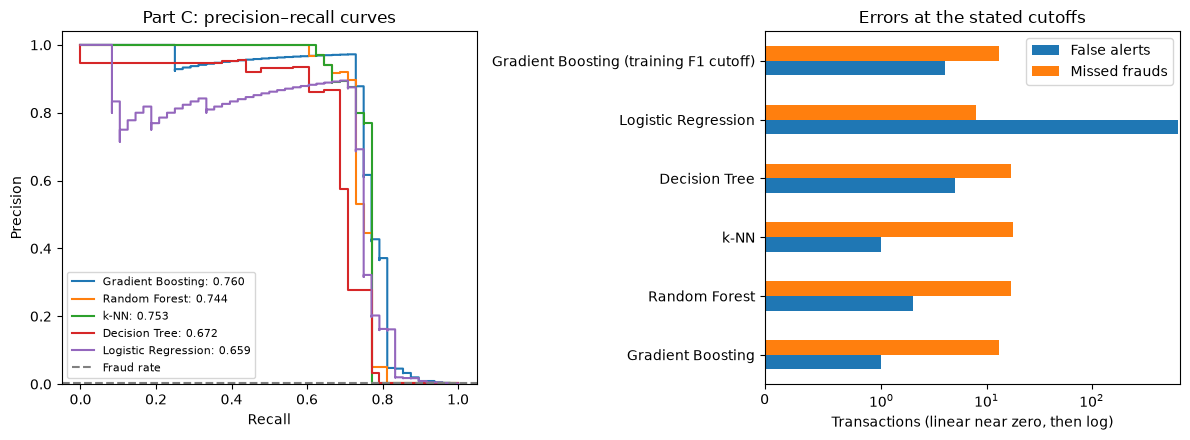

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name in cv_summary.index:
    pp, rr, _ = precision_recall_curve(y_eval, eval_rank[name])
    axes[0].step(rr, pp, where="post", label=f"{name}: {evaluation.loc[name, 'AP']:.3f}")
axes[0].axhline(y_eval.mean(), ls="--", color="gray", label="Fraud rate")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Part C: precision–recall curves", ylim=(0, 1.04))
axes[0].legend(fontsize=8)
bar_data = evaluation.loc[list(cv_summary.index) + [alternative], ["FP", "FN"]]
bar_data.rename(columns={"FP":"False alerts", "FN":"Missed frauds"}).plot.barh(ax=axes[1])
axes[1].set_xscale("symlog", linthresh=1)
axes[1].set(xlabel="Transactions (linear near zero, then log)", ylabel="", title="Errors at the stated cutoffs")
plt.tight_layout()
plt.show()

### What do the errors mean?
The comparisons below use counts as well as percentages. Changing the cutoff changes which transactions are flagged but leaves their ranking, AP, and ROC-AUC unchanged. The number missed by all five models is measured on the same rows at cutoff 0.50; it does not prove those frauds are intrinsically undetectable.

In [26]:
default = evaluation.loc[selected]
changed = evaluation.loc[alternative]
linear = evaluation.loc["Logistic Regression"]
print(f"At 0.50, {selected} caught {int(default.TP)}/{int(y_eval.sum())} frauds "
      f"and issued {int(default.FP)} false alerts; precision {default.Precision:.1%}.")
print(f"Logistic Regression caught {int(linear.TP)} and issued {int(linear.FP)} false alerts.")
print(f"With the training-selected cutoff, {selected} caught {int(changed.TP)} "
      f"and issued {int(changed.FP)} false alerts. F1: {default.F1:.3f} → {changed.F1:.3f}.")
missed_by_all = (y_eval == 1) & (eval_scores < 0.5).all(axis=1)
print(f"Confirmed frauds missed by every model at 0.50: {int(missed_by_all.sum())}.")
print(f"One fraud in this evaluation changes recall by {100 / y_eval.sum():.1f} percentage points.")
print("The cutoff " + ("improved" if changed.F1 > default.F1 else
      "reduced" if changed.F1 < default.F1 else "did not change") +
      " F1 on these unseen rows. Keep this result, without tuning again on these rows.")

At 0.50, Gradient Boosting caught 35/48 frauds and issued 1 false alerts; precision 97.2%.
Logistic Regression caught 40 and issued 659 false alerts.
With the training-selected cutoff, Gradient Boosting caught 35 and issued 4 false alerts. F1: 0.833 → 0.805.
Confirmed frauds missed by every model at 0.50: 8.
One fraud in this evaluation changes recall by 2.1 percentage points.
The cutoff reduced F1 on these unseen rows. Keep this result, without tuning again on these rows.


# Part D · Independent investigation: cost-sensitive decisions (Track A)

**Written before running any Part D experiment and before using `X_final`.**

**Question.** For the locked Gradient Boosting model, does an *amount-aware* decision rule cost less on unseen transactions than (a) the default 0.50 cutoff and (b) the best single cutoff chosen for cost?

**Costs.**
- *Missed fraud (FN):* the transaction amount, which is lost money. A missed €2,000 fraud costs far more than a missed €2 fraud, so we use each transaction's own amount and not one fixed number.
- *Alert (TP or FP):* a fixed review cost **C = €5** per alert (analyst time and customer contact). This is our assumption, not a published figure, so we also report C = €1, 2, 10, 20, 50.
- *Correctly ignored legitimate transaction (TN):* €0.
- Customer annoyance from false alerts and the chargeback process are not priced. They are discussed as limitations.

**Decision policies (all set using training out-of-fold scores only):**
1. **Default:** alert if p ≥ 0.50 (the Part B/C setting).
2. **Global cost cutoff:** one cutoff t that minimises total training cost.
3. **Amount-aware rule:** alert if p × Amount ≥ C. This is the expected-cost rule: alerting costs C, and not alerting costs p × Amount on average. It needs no tuning, but it assumes the probabilities are well calibrated. So we also test an isotonic-calibrated version and keep whichever has the lower *cross-fitted* training cost at C = €5.

Reference points: *never alert* (cost = all fraud amounts) and *alert on everything*.

**Hypothesis.** On `X_final`: amount-aware < global cutoff < default, in total cost at C = €5.

**Protocol.** `X_final` is scored once, after the policies are fixed. We report total cost, frauds and euros caught, alerts, and a paired bootstrap 95% interval for the cost differences, because `X_final` contains only ~47 frauds.

In [27]:
from sklearn.isotonic import IsotonicRegression

REVIEW_COST = 5.0
COST_GRID = [1, 2, 5, 10, 20, 50]

def total_cost(alerts, labels, amounts, review_cost):
    alerts, labels, amounts = np.asarray(alerts, bool), np.asarray(labels), np.asarray(amounts, float)
    return review_cost * alerts.sum() + amounts[(labels == 1) & ~alerts].sum()

def best_global_cutoff(scores, labels, amounts, review_cost):
    """Exact search: alerting the top-k scores costs review_cost*k + fraud amounts left below the cut."""
    scores, labels, amounts = np.asarray(scores), np.asarray(labels), np.asarray(amounts, float)
    order = np.argsort(-scores, kind="mergesort")
    s = scores[order]
    fraud_amt = np.where(labels[order] == 1, amounts[order], 0.0)
    cost_top_k = review_cost * np.arange(1, len(s) + 1) + fraud_amt.sum() - np.cumsum(fraud_amt)
    valid = np.r_[s[:-1] > s[1:], True]          # only cut between different scores
    k = np.flatnonzero(valid)[np.argmin(cost_top_k[valid])]
    if fraud_amt.sum() <= cost_top_k[k]:          # alerting nothing is cheaper
        return np.inf
    return float(s[k])

def amount_rule(scores, amounts, review_cost):
    return np.asarray(scores) * np.asarray(amounts, float) >= review_cost

train_scores = oof_proba[selected].to_numpy()
train_amounts = X_train["Amount"].to_numpy()
train_labels = y_train.to_numpy()
print(f"Training frauds: {train_labels.sum()}, total fraud amount €{train_amounts[train_labels == 1].sum():,.0f}")
print(f"Frauds under €{REVIEW_COST:.0f}: {(train_amounts[train_labels == 1] < REVIEW_COST).mean():.0%} "
      "(the amount-aware rule can never alert on these, because p ≤ 1)")

Training frauds: 378, total fraud amount €43,825
Frauds under €5: 44% (the amount-aware rule can never alert on these, because p ≤ 1)


### Are the probabilities calibrated? (training out-of-fold only)
The amount-aware rule uses p directly, so we compare the predicted probability with the observed fraud rate in each score band.

In [28]:
bands = pd.cut(train_scores, [0, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0001], right=False)
calib = (pd.DataFrame({"p": train_scores, "fraud": train_labels, "band": bands})
         .groupby("band", observed=True)
         .agg(rows=("fraud", "size"), mean_predicted=("p", "mean"), observed_rate=("fraud", "mean")))
display(calib.round(4))

,rows,mean_predicted,observed_rate
band,,,
"[0.0, 0.01)",226466,0.0001,0.0003
"[0.01, 0.05)",147,0.0232,0.0816
"[0.05, 0.1)",20,0.0645,0.2500
"[0.1, 0.3)",29,0.1752,0.3793
"[0.3, 0.5)",13,0.4108,0.4615
"[0.5, 0.7)",12,0.6213,0.6667
"[0.7, 0.9)",22,0.8183,0.7727
"[0.9, 1.0)",271,0.9805,0.9631


### Choosing between policies using training data only (cross-fitted)
For each of the five Part A folds we set the cutoff and calibrator on the other four folds' out-of-fold scores, then measure cost on the held-out fold. This shows how each policy does on rows it was not tuned on, without touching `X_final`.

In [29]:
xfit = {c: dict.fromkeys(["Default 0.50", "Global cutoff", "Amount-aware", "Amount-aware + calibration"], 0.0)
        for c in COST_GRID}
for c in COST_GRID:
    for fit_idx, val_idx in cv_splits:
        s_fit, s_val = train_scores[fit_idx], train_scores[val_idx]
        a_fit, a_val = train_amounts[fit_idx], train_amounts[val_idx]
        y_fit, y_val = train_labels[fit_idx], train_labels[val_idx]
        cut = best_global_cutoff(s_fit, y_fit, a_fit, c)
        iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(s_fit, y_fit)
        xfit[c]["Default 0.50"] += total_cost(s_val >= 0.5, y_val, a_val, c)
        xfit[c]["Global cutoff"] += total_cost(s_val >= cut, y_val, a_val, c)
        xfit[c]["Amount-aware"] += total_cost(amount_rule(s_val, a_val, c), y_val, a_val, c)
        xfit[c]["Amount-aware + calibration"] += total_cost(amount_rule(iso.predict(s_val), a_val, c), y_val, a_val, c)
xfit = pd.DataFrame(xfit).T
xfit.index.name = "Review cost (€)"
display(xfit.round(0))

use_calibration = xfit.loc[REVIEW_COST, "Amount-aware + calibration"] < xfit.loc[REVIEW_COST, "Amount-aware"]
print(f"At €{REVIEW_COST:.0f} per alert, calibration {'is' if use_calibration else 'is not'} kept for the amount-aware rule.")

,Default 0.50,Global cutoff,Amount-aware,Amount-aware + calibration
Review cost (€),,,,
1,16419.0,11917.0,9725.0,6751.0
2,16724.0,12532.0,11233.0,9170.0
5,17639.0,13149.0,12371.0,13177.0
10,19164.0,16084.0,13126.0,14027.0
20,22214.0,20024.0,14611.0,15751.0
50,31364.0,34823.0,20074.0,19493.0


At €5 per alert, calibration is not kept for the amount-aware rule.


### Lock the policies, then score `X_final` once
Cutoffs and the calibrator are now refitted on all training out-of-fold scores. Nothing below is changed after seeing `X_final`.

In [30]:
def fit_policies(review_cost):
    cut = best_global_cutoff(train_scores, train_labels, train_amounts, review_cost)
    iso = IsotonicRegression(y_min=0, y_max=1, out_of_bounds="clip").fit(train_scores, train_labels)
    calibrated = xfit.loc[review_cost, "Amount-aware + calibration"] < xfit.loc[review_cost, "Amount-aware"]
    def apply(scores, amounts):
        p = iso.predict(scores) if calibrated else scores
        return {
            "Never alert": np.zeros(len(scores), bool),
            "Alert on everything": np.ones(len(scores), bool),
            "Default 0.50": scores >= 0.5,
            "Global cutoff": scores >= cut,
            "Amount-aware": amount_rule(p, amounts, review_cost),
        }
    return apply, cut, calibrated

apply_policies, locked_cut, _ = fit_policies(REVIEW_COST)
print(f"Locked global cutoff at €{REVIEW_COST:.0f}: {locked_cut:.4g}")

# ---- the only place X_final is used ----
final_scores = best_pipelines[selected].predict_proba(X_final)[:, list(best_pipelines[selected].classes_).index(1)]
final_amounts = X_final["Amount"].to_numpy()
final_labels = y_final.to_numpy()
final_alerts = apply_policies(final_scores, final_amounts)

rows = {}
fraud_total = final_amounts[final_labels == 1].sum()
for name, alerts in final_alerts.items():
    caught = (final_labels == 1) & alerts
    rows[name] = {
        "Total cost (€)": total_cost(alerts, final_labels, final_amounts, REVIEW_COST),
        "Alerts": int(alerts.sum()),
        "Frauds caught": f"{int(caught.sum())}/{int(final_labels.sum())}",
        "False alerts": int((alerts & (final_labels == 0)).sum()),
        "Fraud € caught": final_amounts[caught].sum(),
        "Share of fraud € caught": final_amounts[caught].sum() / fraud_total,
    }
final_table = pd.DataFrame(rows).T
final_table["Saving vs never alert (€)"] = final_table.loc["Never alert", "Total cost (€)"] - final_table["Total cost (€)"]
print(f"X_final: {len(final_labels):,} rows, {int(final_labels.sum())} frauds, fraud amount €{fraud_total:,.0f}")
display(final_table)

Locked global cutoff at €5: 0.01714
X_final: 28,373 rows, 47 frauds, fraud amount €4,447


,Total cost (€),Alerts,Frauds caught,False alerts,Fraud € caught,Share of fraud € caught,Saving vs never alert (€)
Never alert,4446.67,0,0/47,0,0.0,0.0,0.0
Alert on everything,141865.0,28373,47/47,28326,4446.67,1.0,-137418.33
Default 0.50,1523.11,37,35/47,2,3108.56,0.699076,2923.56
Global cutoff,1596.07,59,37/47,22,3145.6,0.707406,2850.6
Amount-aware,1520.81,37,19/47,18,3110.86,0.699593,2925.86


### How sure are we? Paired bootstrap on `X_final`
We resample the final rows 2,000 times and recompute the cost difference between policies on the same resampled rows. If an interval contains 0, the difference is not reliable.

In [31]:
def row_costs(alerts):
    return np.where(alerts, REVIEW_COST, np.where(final_labels == 1, final_amounts, 0.0))

rng = np.random.default_rng(RANDOM_STATE)
boot_idx = rng.integers(0, len(final_labels), size=(2000, len(final_labels)))
pairs = [("Amount-aware", "Default 0.50"), ("Amount-aware", "Global cutoff"), ("Global cutoff", "Default 0.50")]
boot_rows = {}
for a, b in pairs:
    diff = row_costs(final_alerts[a]) - row_costs(final_alerts[b])
    sims = diff[boot_idx].sum(axis=1)
    boot_rows[f"{a} − {b}"] = {"Observed (€)": diff.sum(), "2.5%": np.percentile(sims, 2.5),
                               "97.5%": np.percentile(sims, 97.5), "Share of resamples < 0": (sims < 0).mean()}
display(pd.DataFrame(boot_rows).T.round(2))
print("Negative = the first policy is cheaper.")

,Observed (€),2.5%,97.5%,Share of resamples < 0
Amount-aware − Default 0.50,-2.30,-63.31,55.14,0.52
Amount-aware − Global cutoff,-75.26,-134.82,-14.42,0.99
Global cutoff − Default 0.50,72.96,13.92,130.02,0.01


Negative = the first policy is cheaper.


### Sensitivity to the review cost (secondary, declared in advance)
For each review cost, the policies are refitted on training data only and then applied to the same `X_final` scores.

,Never alert,Default 0.50,Global cutoff,Amount-aware
Review cost (€),,,,
1,4447.0,1375.0,1696.0,846.0
2,4447.0,1412.0,1425.0,857.0
5,4447.0,1523.0,1596.0,1521.0
10,4447.0,1708.0,1791.0,1587.0
20,4447.0,2078.0,2281.0,1747.0
50,4447.0,3188.0,3188.0,2330.0


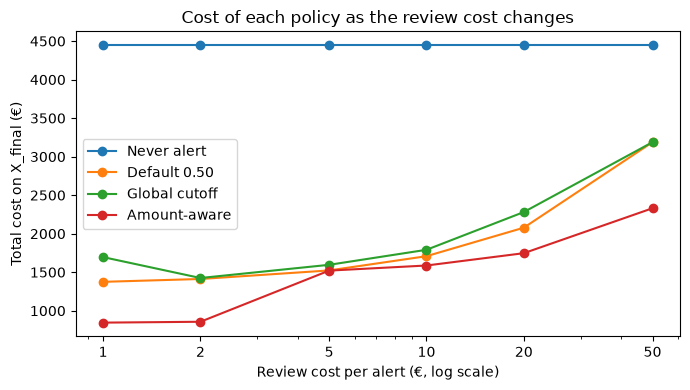

In [32]:
sens = {}
for c in COST_GRID:
    apply_c, cut_c, cal_c = fit_policies(c)
    alerts_c = apply_c(final_scores, final_amounts)
    sens[c] = {name: total_cost(al, final_labels, final_amounts, c) for name, al in alerts_c.items()
               if name != "Alert on everything"}
sens = pd.DataFrame(sens).T
sens.index.name = "Review cost (€)"
display(sens.round(0))

fig, ax = plt.subplots(figsize=(7, 4))
for name in ["Never alert", "Default 0.50", "Global cutoff", "Amount-aware"]:
    ax.plot(sens.index, sens[name], marker="o", label=name)
ax.set_xscale("log")
ax.set_xticks(COST_GRID, [str(c) for c in COST_GRID])
ax.set(xlabel="Review cost per alert (€, log scale)", ylabel="Total cost on X_final (€)",
       title="Cost of each policy as the review cost changes")
ax.legend()
plt.tight_layout()
plt.show()

### Which frauds does the amount-aware rule give up?

In [33]:
missed = (final_labels == 1) & ~final_alerts["Amount-aware"]
missed_default = (final_labels == 1) & ~final_alerts["Default 0.50"]
print(f"Amount-aware rule missed {missed.sum()} frauds worth €{final_amounts[missed].sum():,.2f} "
      f"(default 0.50 missed {missed_default.sum()} worth €{final_amounts[missed_default].sum():,.2f}).")
print(f"Of the amount-aware misses, {(final_amounts[missed] < REVIEW_COST).sum()} are under €{REVIEW_COST:.0f} "
      "and could never be flagged by this rule.")
missed_table = pd.DataFrame({"Amount (€)": final_amounts[missed], "Model score": final_scores[missed],
                             "Flagged at 0.50": final_alerts["Default 0.50"][missed]}).sort_values("Amount (€)", ascending=False)
display(missed_table.round(4))

Amount-aware rule missed 28 frauds worth €1,335.81 (default 0.50 missed 12 worth €1,338.11).
Of the amount-aware misses, 23 are under €5 and could never be flagged by this rule.


,Amount (€),Model score,Flagged at 0.50
6,723.21,0.0007,False
9,549.06,0.0000,False
19,18.00,0.0868,False
14,12.31,0.0123,False
25,8.00,0.0006,False
0,3.79,0.9807,True
10,3.79,0.0104,False
4,2.22,0.0132,False
1,2.00,0.9989,True
27,1.18,0.9846,True


### Part D results and discussion
*(Numbers refer to the run saved in this notebook. A re-run can shift them slightly.)*

**Answer to the question: not supported at the planned cost of €5 per alert.**
- The amount-aware rule cost **€1,521** against **€1,523** for the default 0.50 cutoff. The bootstrap interval for the difference (about −€63 to +€55) contains 0, so this is a tie.
- The global cost cutoff was **worse** than the default (**€1,596**, about €73 more, interval +€14 to +€130), even though it was clearly better on the cross-fitted training data.

**At every other review cost the amount-aware rule was cheapest on `X_final`.** At €1–2 per alert it cost about 40% less than the default (for example €846 vs €1,375 at €1). At €50 it cost about 27% less (€2,330 vs €3,188). This ordering matches the cross-fitted training results, so €5 turned out to be close to the point where the two rules break even on this sample.

**What the amount-aware rule changes.** It raised about the same number of alerts as the default and caught about the same share of fraud *money* (≈70%). It did this by giving up many *small* frauds (19/47 frauds caught by count vs 35/47) in exchange for more alerts on larger, lower-scored transactions. Most of its misses are under €5, and many are €0–€1.

**What did not work**
- *Global cost cutoff:* the cutoff that minimised training cost (≈0.017) added 22 alerts on `X_final` but caught only 2 extra frauds. With about 47 frauds, a handful of cases decides the result. Also, the training scores come from fold models while `X_final` is scored by the model refitted on all training data, so the scores near such a low cutoff may not mean the same thing.
- *Calibration:* isotonic calibration fixed the under-confident low scores (training rows scored 1–5% were fraud about 8% of the time) and helped when alerts are very cheap (€1–2). At €5 it did not help on cross-fitted training data, so it was not used there.
- *Model blind spots:* two of the largest frauds in `X_final` (€723 and €549) got scores near 0. No decision rule can recover these. They need better features or a different model, not a different cutoff.

**Limitations and ethics**
- The €5 review cost is an assumption. The conclusion depends on it, which is why the sensitivity table matters.
- Treating a missed fraud as costing only its amount ignores chargeback fees, customer harm and lost trust. Small "test" transactions often come before larger fraud on the same card, so an amount-aware rule that ignores them could cost more later. This needs a policy decision, for example always reviewing very high-score transactions whatever their amount.
- False alerts block real customers' payments. If transaction amounts differ between customer groups, an amount-based rule protects some groups more than others. We cannot check this because the features are anonymised.
- The data covers two days of European card transactions from 2013. Fraud patterns change, so cutoffs and costs would need regular re-checking.

## References
1. Machine Learning Group – ULB. *Credit Card Fraud Detection* dataset. Kaggle. https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
2. Dal Pozzolo, A., Caelen, O., Johnson, R. A., & Bontempi, G. (2015). Calibrating probability with undersampling for unbalanced classification. *IEEE Symposium Series on Computational Intelligence*.
3. Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
4. Elkan, C. (2001). The foundations of cost-sensitive learning. *Proceedings of IJCAI*.
5. Correa Bahnsen, A., Aouada, D., & Ottersten, B. (2015). Example-dependent cost-sensitive decision trees. *Expert Systems with Applications*, 42(19).
6. Zadrozny, B., & Elkan, C. (2002). Transforming classifier scores into accurate multiclass probability estimates. *Proceedings of KDD*.
7. Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
8. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.

## AI-Assistance Declaration

ChatGPT (OpenAI) and Claude (Anthropic) were used as assistance tools 
throughout the development of this project for the following purposes:

**ChatGPT (OpenAI):**

- Improving the readability, structure, and organization of the code.
- Dividing the notebook into logical sections, providing appropriate 
  titles, and adding descriptions to explain the purpose of each section.
- Reviewing the code to identify potential weaknesses, errors, and areas 
  for improvement.
- Suggesting improvements to code quality, consistency, and efficiency.

**Claude (Anthropic):**

- Generating a PowerPoint presentation template.
- Structuring and organizing the ideas presented in the slides to ensure 
  a clear and coherent flow.
- Assisting in structuring and organizing the project report.

AI-generated suggestions were used to refine the code, documentation, 
report, and presentation. The project team takes full responsibility 
for the final implementation, methodology, results, and conclusions.

In [40]:
df.loc[True, "Class"]

KeyError: True